# AIML Lab Exercise 7: Decision Tree using the ID3 Algorithm
**Dataset:** PlayTennis Dataset (play_tennis.csv)

This notebook demonstrates the working of the **ID3 (Iterative Dichotomiser 3)** decision tree algorithm. ID3 builds the tree top-down: at every node it chooses the attribute with the **highest information gain**, splits the data on that attribute, and repeats on each subset until the subsets are pure. The algorithm is implemented **from scratch** and then compared with scikit-learn's `DecisionTreeClassifier`.

## 1. Import the required libraries

In [1]:
import math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset
The PlayTennis dataset has 14 days of weather observations and whether tennis was played on that day.

In [2]:
df = pd.read_csv('play_tennis.csv')
print("Dataset loaded successfully! Shape:", df.shape)
display(df)

target = 'PlayTennis'
attributes = [c for c in df.columns if c != target]
print("Attributes:", attributes)
print("Target    :", target, df[target].value_counts().to_dict())

Dataset loaded successfully! Shape: (14, 5)


,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


Attributes: ['Outlook', 'Temperature', 'Humidity', 'Wind']
Target    : PlayTennis {'Yes': 9, 'No': 5}


## 3. Entropy
Entropy measures the impurity (uncertainty) of a set *S*:

$$Entropy(S) = -\sum_{i=1}^{c} p_i \log_2 p_i$$

It is 0 when all examples belong to one class and 1 when a binary set is split 50/50.

Entropy of the full dataset (9 Yes, 5 No): 0.9403


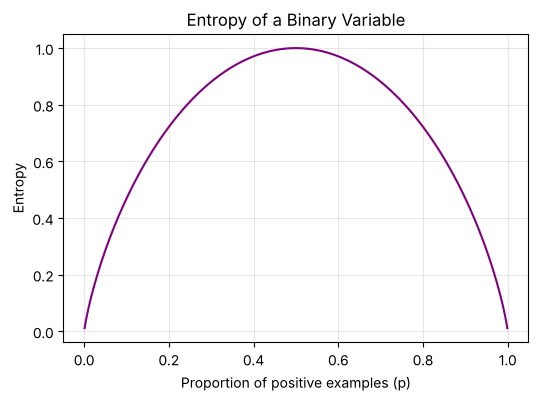

In [3]:
def entropy(labels):
    total = len(labels)
    return -sum((count / total) * math.log2(count / total) for count in Counter(labels).values()) + 0.0  # + 0.0 avoids printing -0.0

print(f"Entropy of the full dataset (9 Yes, 5 No): {entropy(df[target]):.4f}")

p = np.linspace(0.001, 0.999, 200)
plt.figure(figsize=(6, 4))
plt.plot(p, -p * np.log2(p) - (1 - p) * np.log2(1 - p), color='purple')
plt.xlabel('Proportion of positive examples (p)')
plt.ylabel('Entropy')
plt.title('Entropy of a Binary Variable')
plt.grid(alpha=0.3)
plt.show()

## 4. Information gain
Information gain is the reduction in entropy obtained by splitting *S* on attribute *A*:

$$Gain(S, A) = Entropy(S) - \sum_{v \in Values(A)} \frac{|S_v|}{|S|} Entropy(S_v)$$

In [4]:
def information_gain(data, attribute, target):
    total_entropy = entropy(data[target])
    weighted_entropy = sum((len(subset) / len(data)) * entropy(subset[target])
                           for _, subset in data.groupby(attribute))
    return total_entropy - weighted_entropy

# Detailed calculation for the attribute 'Outlook'
for value, subset in df.groupby('Outlook'):
    counts = subset[target].value_counts().to_dict()
    print(f"Outlook = {value:8s}: {counts}, entropy = {entropy(subset[target]):.4f}")
print(f"\nGain(S, Outlook) = {information_gain(df, 'Outlook', target):.4f}")

Outlook = Overcast: {'Yes': 4}, entropy = 0.0000
Outlook = Rain    : {'Yes': 3, 'No': 2}, entropy = 0.9710
Outlook = Sunny   : {'No': 3, 'Yes': 2}, entropy = 0.9710

Gain(S, Outlook) = 0.2467


## 5. Choose the root node: information gain of every attribute

,Information Gain
Outlook,0.2467
Humidity,0.1518
Wind,0.0481
Temperature,0.0292


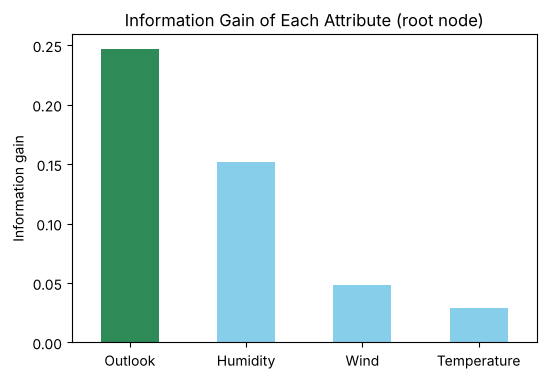

Best attribute for the root node: Outlook


In [5]:
gains = pd.Series({a: information_gain(df, a, target) for a in attributes}).sort_values(ascending=False)
display(gains.to_frame('Information Gain').round(4))

plt.figure(figsize=(6, 4))
gains.plot.bar(color=['seagreen'] + ['skyblue'] * (len(gains) - 1), rot=0)
plt.ylabel('Information gain')
plt.title('Information Gain of Each Attribute (root node)')
plt.show()
print("Best attribute for the root node:", gains.idxmax())

## 6. Implement the ID3 algorithm
**ID3(S, attributes):**
1. If all examples in *S* have the same class → return a **leaf** with that class.
2. If no attributes are left → return a leaf with the **majority class**.
3. Otherwise choose the attribute *A* with the highest information gain as the decision node.
4. For each value *v* of *A*, create a branch and call **ID3(Sᵥ, attributes − {A})**.

The tree is stored as a nested dictionary: `{attribute: {value: subtree_or_label}}`.

In [6]:
def id3(data, attributes, target, depth=0, log=True):
    labels = data[target]
    if labels.nunique() == 1:                       # pure node -> leaf
        return labels.iloc[0]
    if not attributes:                              # no attributes left -> majority class
        return labels.mode()[0]

    gains = {a: information_gain(data, a, target) for a in attributes}
    best = max(gains, key=gains.get)
    if log:
        print("    " * depth + f"Split on '{best}' (gain = {gains[best]:.4f}) with {len(data)} samples")

    tree = {best: {}}
    remaining = [a for a in attributes if a != best]
    for value, subset in data.groupby(best):
        tree[best][value] = id3(subset, remaining, target, depth + 1, log)
    return tree

decision_tree = id3(df, attributes, target)

Split on 'Outlook' (gain = 0.2467) with 14 samples
    Split on 'Wind' (gain = 0.9710) with 5 samples
    Split on 'Humidity' (gain = 0.9710) with 5 samples


## 7. Display the learned decision tree

In [7]:
def print_tree(tree, indent=''):
    if not isinstance(tree, dict):
        print(indent + '-> ' + str(tree))
        return
    attribute = next(iter(tree))
    for value, subtree in tree[attribute].items():
        print(f"{indent}[{attribute} = {value}]")
        print_tree(subtree, indent + '    ')

print("Nested dictionary:\n", decision_tree, "\n")
print_tree(decision_tree)

Nested dictionary:
 {'Outlook': {'Overcast': 'Yes', 'Rain': {'Wind': {'Strong': 'No', 'Weak': 'Yes'}}, 'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}}} 

[Outlook = Overcast]
    -> Yes
[Outlook = Rain]
    [Wind = Strong]
        -> No
    [Wind = Weak]
        -> Yes
[Outlook = Sunny]
    [Humidity = High]
        -> No
    [Humidity = Normal]
        -> Yes


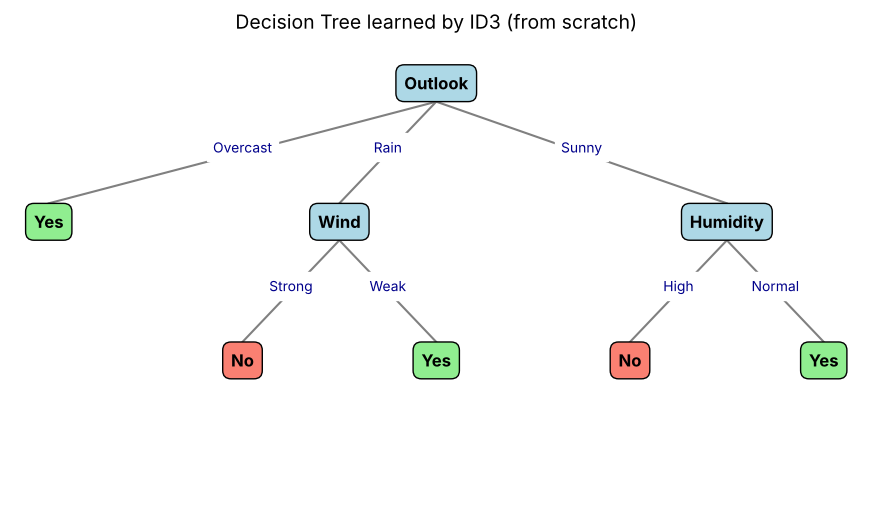

In [8]:
def plot_id3_tree(tree):
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.axis('off')
    leaves = []

    def count_leaves(t):
        if not isinstance(t, dict):
            return 1
        return sum(count_leaves(s) for s in next(iter(t.values())).values())

    def draw(t, x_left, x_right, y, parent_xy=None, edge_label=''):
        x = (x_left + x_right) / 2
        if isinstance(t, dict):
            text, color = next(iter(t)), 'lightblue'
        else:
            text, color = t, 'lightgreen' if t == 'Yes' else 'salmon'
        if parent_xy:
            ax.plot([parent_xy[0], x], [parent_xy[1] - 0.04, y + 0.04], color='gray')
            ax.text((parent_xy[0] + x) / 2, (parent_xy[1] + y) / 2, edge_label, ha='center',
                    fontsize=10, color='darkblue', backgroundcolor='white')
        ax.text(x, y, text, ha='center', va='center', fontsize=12, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor=color, edgecolor='black'))
        if isinstance(t, dict):
            children = t[text]
            total = count_leaves(t)
            start = x_left
            for value, child in children.items():
                width = (x_right - x_left) * count_leaves(child) / total
                draw(child, start, start + width, y - 0.3, (x, y), str(value))
                start += width

    draw(tree, 0, 1, 0.9)
    ax.set_ylim(0, 1)
    ax.set_title('Decision Tree learned by ID3 (from scratch)', fontsize=14)
    plt.show()

plot_id3_tree(decision_tree)

**Interpretation:** `Outlook` is the root. If it is *Overcast*, tennis is always played. If it is *Sunny*, the decision depends on `Humidity`; if it is *Rain*, the decision depends on `Wind`. `Temperature` was never needed.

## 8. Classify new samples using the learned tree
If a value never seen during training appears, the function falls back to the majority class.

In [9]:
majority_class = df[target].mode()[0]

def classify(tree, sample, default=majority_class):
    while isinstance(tree, dict):
        attribute = next(iter(tree))
        value = sample.get(attribute)
        if value not in tree[attribute]:
            return default
        tree = tree[attribute][value]
    return tree

new_samples = pd.DataFrame([
    {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'},
    {'Outlook': 'Rain', 'Temperature': 'Mild', 'Humidity': 'Normal', 'Wind': 'Weak'},
    {'Outlook': 'Overcast', 'Temperature': 'Hot', 'Humidity': 'High', 'Wind': 'Strong'},
    {'Outlook': 'Sunny', 'Temperature': 'Mild', 'Humidity': 'Normal', 'Wind': 'Weak'},
])
new_samples['Predicted PlayTennis'] = [classify(decision_tree, row) for row in new_samples.to_dict('records')]
display(new_samples)

,Outlook,Temperature,Humidity,Wind,Predicted PlayTennis
0,Sunny,Cool,High,Strong,No
1,Rain,Mild,Normal,Weak,Yes
2,Overcast,Hot,High,Strong,Yes
3,Sunny,Mild,Normal,Weak,Yes


## 9. Accuracy on the training data and leave-one-out evaluation
The tree classifies every training example correctly. To estimate how well it generalises, we also use **leave-one-out cross-validation**: build the tree on 13 examples and test it on the remaining one, for each of the 14 examples.

In [10]:
train_pred = [classify(decision_tree, row) for row in df[attributes].to_dict('records')]
print("Training accuracy:", np.mean(np.array(train_pred) == df[target].values))

correct = 0
for i in range(len(df)):
    train_part = df.drop(index=i)
    tree_i = id3(train_part, attributes, target, log=False)
    prediction = classify(tree_i, df.loc[i, attributes].to_dict(), default=train_part[target].mode()[0])
    correct += prediction == df.loc[i, target]
print(f"Leave-one-out accuracy: {correct}/{len(df)} = {correct / len(df):.4f}")

Training accuracy: 1.0


Leave-one-out accuracy: 11/14 = 0.7857


## 10. Compare with scikit-learn's DecisionTreeClassifier (criterion = 'entropy')
scikit-learn needs numeric input, so the categorical attributes are one-hot encoded. Its tree makes binary splits (e.g. *Outlook_Overcast ≤ 0.5*), but it uses the same entropy / information-gain criterion.

scikit-learn training accuracy: 1.0

|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rain <= 0.50
|   |   |   |--- class: No
|   |   |--- Outlook_Rain >  0.50
|   |   |   |--- Wind_Strong <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- Wind_Strong >  0.50
|   |   |   |   |--- class: No
|   |--- Humidity_Normal >  0.50
|   |   |--- Wind_Strong <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Wind_Strong >  0.50
|   |   |   |--- Outlook_Sunny <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Outlook_Sunny >  0.50
|   |   |   |   |--- class: Yes
|--- Outlook_Overcast >  0.50
|   |--- class: Yes



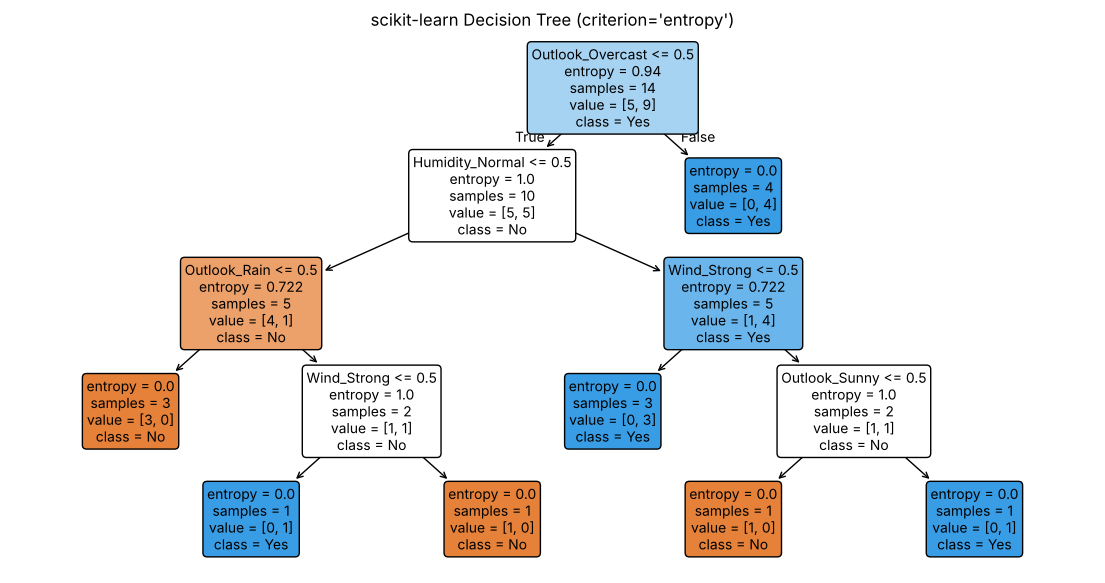

In [11]:
X_encoded = pd.get_dummies(df[attributes]).astype(int)
y = df[target]

sk_tree = DecisionTreeClassifier(criterion='entropy', random_state=42)
sk_tree.fit(X_encoded, y)
print("scikit-learn training accuracy:", sk_tree.score(X_encoded, y))
print("\n" + export_text(sk_tree, feature_names=list(X_encoded.columns)))

plt.figure(figsize=(14, 7))
plot_tree(sk_tree, feature_names=X_encoded.columns, class_names=sk_tree.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("scikit-learn Decision Tree (criterion='entropy')")
plt.show()

## 11. Documentation summary
1. Loaded the PlayTennis dataset
2. Implemented the entropy function and computed the entropy of the dataset (0.940)
3. Implemented information gain and computed it for every attribute — `Outlook` has the highest gain (0.247) and becomes the root
4. Implemented the ID3 algorithm recursively and displayed the learned tree as text and as a diagram
5. Classified new samples using the tree
6. Measured training accuracy and leave-one-out accuracy
7. Compared the result with scikit-learn's `DecisionTreeClassifier` using the entropy criterion

**Result:** The ID3 decision tree was built successfully: **Outlook** is the root node, **Humidity** decides the *Sunny* branch and **Wind** decides the *Rain* branch.